# Lesson 02 — From Q-tables to Deep Q-Networks

**Driving question:** How can an agent learn action values when observations no longer fit neatly into a table?

**Time:** 60 minutes · **Prerequisite:** Lesson 01 and Python/NumPy · **Dependencies:** PyTorch, Gymnasium classic-control, NumPy, Matplotlib · **Runs on CPU**

Like Lesson 01, this is a guided experiment: **predict → execute → inspect → explain**. No neural-network background is assumed.

By the end you should be able to explain why a Q-table can become limiting, read Gymnasium's API, trace one DQN update, explain replay and target networks, and evaluate a learned policy fairly.

**Before running:** Predict whether a trained agent will balance the pole longer than a random agent. What evidence would change your mind?

> My prediction: ...

### Setup
Open this notebook in the workshop's Python environment. Use **Restart Kernel and Run All** to reproduce the complete experiment. The setup locates the workshop from either its root or this lesson folder. Outputs are written under `outputs/lesson02_notebook/` beneath the directory containing `lessons/`, matching Lesson 01.

In [1]:
from pathlib import Path
from collections import deque
from copy import deepcopy
from dataclasses import dataclass
import csv
import os
import random
import time

# RGB rendering works without a desktop window or external video encoder.
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")
import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, Image, display

module_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "lessons").is_dir()), None)
if module_root is None:
    repo_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                      if (p / "src/lessons").is_dir()), None)
    if repo_root is None:
        raise RuntimeError("Open this notebook from inside the workshop repository")
    module_root = repo_root / "src"
OUTPUT = module_root / "outputs/lesson02_notebook"
OUTPUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)  # Small networks often run faster with one CPU thread.
DEVICE = torch.device("cpu")
TRAIN_SEED = 7
EVAL_SEEDS = tuple(range(2026, 2046))
print("PyTorch:", torch.__version__, "Gymnasium:", gym.__version__)
print("Device:", DEVICE, "Outputs:", OUTPUT)

PyTorch: 2.11.0+cu128 Gymnasium: 1.2.2
Device: cpu Outputs: /workspace/src/outputs/lesson02_notebook


## 1. Meet Gymnasium and CartPole (10 min)

### The task: keep the pole balanced

A pole is attached to a cart that moves left or right along a track. The agent must apply pushes to keep the pole upright while keeping the cart within the allowed track range. It starts near upright, and must respond to both the pole's position and its motion.

Gymnasium supplies the environment and a common interface. The agent chooses an action; `env.step()` applies the dynamics and returns a new observation and reward.

### Action space: what can the agent do?

CartPole uses **`Discrete(2)`**: exactly two possible actions at each step.

| Action | Effect |
|---|---|
| `0` | Apply a force pushing the cart left |
| `1` | Apply a force pushing the cart right |

These are force commands, not destination positions. The agent chooses the direction; it does not choose an arbitrary force magnitude. **Two actions will mean two output Q-values** when we build the network.

### Observation space: what can the agent see?

CartPole uses a continuous **`Box` observation space with shape `(4,)`**. Every observation is a vector of four real-valued measurements:

| Observation index | Meaning | Units |
|---|---|---|
| 0 | Cart position | metres |
| 1 | Cart velocity | metres/second |
| 2 | Pole angle from upright | radians |
| 3 | Pole angular velocity | radians/second |

An **observation dimension** is one component of this vector. This environment therefore has **four observation dimensions**, even though it has only **two actions**. Four measurements will mean four network inputs. Continuous observations and discrete actions are separate properties.

### Reward and episode endings

Default reward is **+1 per step**, including the failure step. There is no extra negative failure reward: failure removes the opportunity to keep earning rewards. The episode terminates when the cart or pole exceeds its failure boundary, or truncates at the wrapper's **500-step time limit**. Observation-space bounds and failure boundaries are different; some observation bounds are infinite.

**Predict before running:** What shapes and action labels will Gymnasium report? Does `action_space.sample()` learn? Does `reset(seed=...)` also seed the action space?


In [2]:
env = gym.make("CartPole-v1")
try:
    observation, info = env.reset(seed=TRAIN_SEED)
    env.action_space.seed(TRAIN_SEED)  # Seed random actions separately.
    print("Observation space:", env.observation_space)
    print("Action space:", env.action_space)
    print("Observation:", observation, "Info:", info)
    action = int(env.action_space.sample())
    next_observation, reward, terminated, truncated, info = env.step(action)
    print("Action:", action, "Next observation:", next_observation)
    print("Reward:", reward, "Terminated:", terminated, "Truncated:", truncated)
    assert next_observation.shape == (4,)
    assert env.observation_space.contains(next_observation)
finally:
    env.close()

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Observation: [ 0.01250955  0.03972138  0.02756857 -0.02747928] Info: {}
Action: 1 Next observation: [ 0.01330397  0.23443735  0.02701898 -0.31133813]
Reward: 1.0 Terminated: False Truncated: False


### Watch one random episode
The following display helper samples rendered RGB frames. Rendering is separate from training. Its frame limit shortens the **preview**, not the training environment.

**Inspect:** Which function chooses an action? Which function decides whether the pole falls?

In [3]:
def animate_policy(model=None, *, seed=2026, title="Random policy", max_frames=125):
    env = gym.make("CartPole-v1", render_mode="rgb_array")
    rng = np.random.default_rng(seed + 10000)
    frames = []
    try:
        obs, _ = env.reset(seed=seed)
        frames.append(env.render()[::2, ::2])
        for _ in range(max_frames - 1):
            if model is None:
                action = int(rng.integers(env.action_space.n))
            else:
                with torch.no_grad():
                    action = int(model(torch.as_tensor(obs).unsqueeze(0)).argmax(1).item())
            obs, _, terminated, truncated, _ = env.step(action)
            frames.append(env.render()[::2, ::2])
            if terminated or truncated:
                break
    finally:
        env.close()
    fig, ax = plt.subplots(figsize=(5, 3))
    image = ax.imshow(frames[0])
    ax.axis("off")
    ax.set_title(title)
    def update(i):
        image.set_data(frames[i])
        return (image,)
    animation = FuncAnimation(fig, update, frames=len(frames), interval=40, blit=True)
    html = animation.to_jshtml()
    plt.close(fig)
    return HTML(html)

display(animate_policy())

/opt/venv/lib/python3.12/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


## 2. Why the observation dimensions matter: the curse of dimensionality (5 min)

You have now seen CartPole's **four continuous measurements** and **two discrete actions** in code and watched a random agent act. How could Lesson 01's Q-table represent this task?

Lesson 01 stored `Q[state, action]` in a **49 × 4 table**: one row for each encoded grid cell and one column per action. Its Bellman sample target was

$$y=r+\gamma\max_{a'}Q(s',a').$$

An exact table cannot enumerate every combination of real-valued observations. One alternative is **discretization**: divide each measurement into bins and use the combination of bin indices as a table row. For the unbounded velocity dimensions, an actual discretization would also need chosen finite ranges and handling for values outside them. The calculation below only estimates table size; it does not implement discretization.

With $b$ bins for each of $d$ observation dimensions and $A$ discrete actions:

$$\text{state bins}=b^d,\qquad \text{Q-table entries}=b^d A.$$

For CartPole, 20 bins per measurement means $20^4=160{,}000$ joint state bins and $160{,}000\times2=320{,}000$ Q-values.

This multiplicative growth is the **curse of dimensionality**: finer resolution multiplies combinations across every dimension, and adding a dimension multiplies them again. Learning useful values throughout a larger table can require much more experience, as well as more memory.

**Predict:** What happens if we double the bins per dimension from 20 to 40? What if a different environment has eight observation dimensions but still only two actions?


In [4]:
observation_dimensions = int(np.prod(env.observation_space.shape))
action_count = env.action_space.n
print(f"CartPole: {observation_dimensions} observation dimensions, {action_count} actions")
for bins in (10, 20, 40):
    state_bins = bins ** observation_dimensions
    entries = state_bins * action_count
    print(f"{bins:2d} bins/dimension: {state_bins:>10,} state bins, "
          f"{entries:>11,} Q-values, {entries * 4 / 1e6:8.2f} MB as float32")
entries_8d = 20 ** 8 * action_count
print(f"8 dimensions at 20 bins each: {entries_8d:,} Q-values; "
      f"{entries_8d * 4 / 1e9:.2f} GB as float32")
print("Doubling bins in four dimensions multiplies table size by:", 2 ** observation_dimensions)
print("Lesson 01:", 49 * 4, "Q-values")

CartPole: 4 observation dimensions, 2 actions
10 bins/dimension:     10,000 state bins,      20,000 Q-values,     0.08 MB as float32
20 bins/dimension:    160,000 state bins,     320,000 Q-values,     1.28 MB as float32
40 bins/dimension:  2,560,000 state bins,   5,120,000 Q-values,    20.48 MB as float32
8 dimensions at 20 bins each: 51,200,000,000 Q-values; 204.80 GB as float32
Doubling bins in four dimensions multiplies table size by: 16
Lesson 01: 196 Q-values


### From the environment to a Q-network

A discretized table can still solve CartPole; the 20-bin example is not, by itself, an unmanageable amount of memory. Its tradeoff is resolution and the experience needed across combinations. More observation dimensions make this tradeoff increasingly difficult.

A **function approximator** instead computes Q-values directly from observations using shared parameters. A neural network is one such function: experience at one observation can also change predictions at other observations. This can help generalization, but errors can also spread.

The environment determines our network's **four inputs** and **two outputs**. The **number and width of hidden layers** are design choices; we will use two hidden layers of 64 neurons each. Increasing hidden width changes the model's capacity, not the number of observation dimensions or available actions.

DQN combines neural Q-value approximation with replay and a target network. It is one useful alternative to a table. Standard DQN selects from discrete actions; continuous observations do not imply continuous actions.


## 3. A network that predicts two Q-values (10 min)

A neuron computes a weighted sum plus a bias. Hidden layers use `ReLU(x) = max(0, x)` to model nonlinear relationships. A **forward pass** transforms observations into predictions:

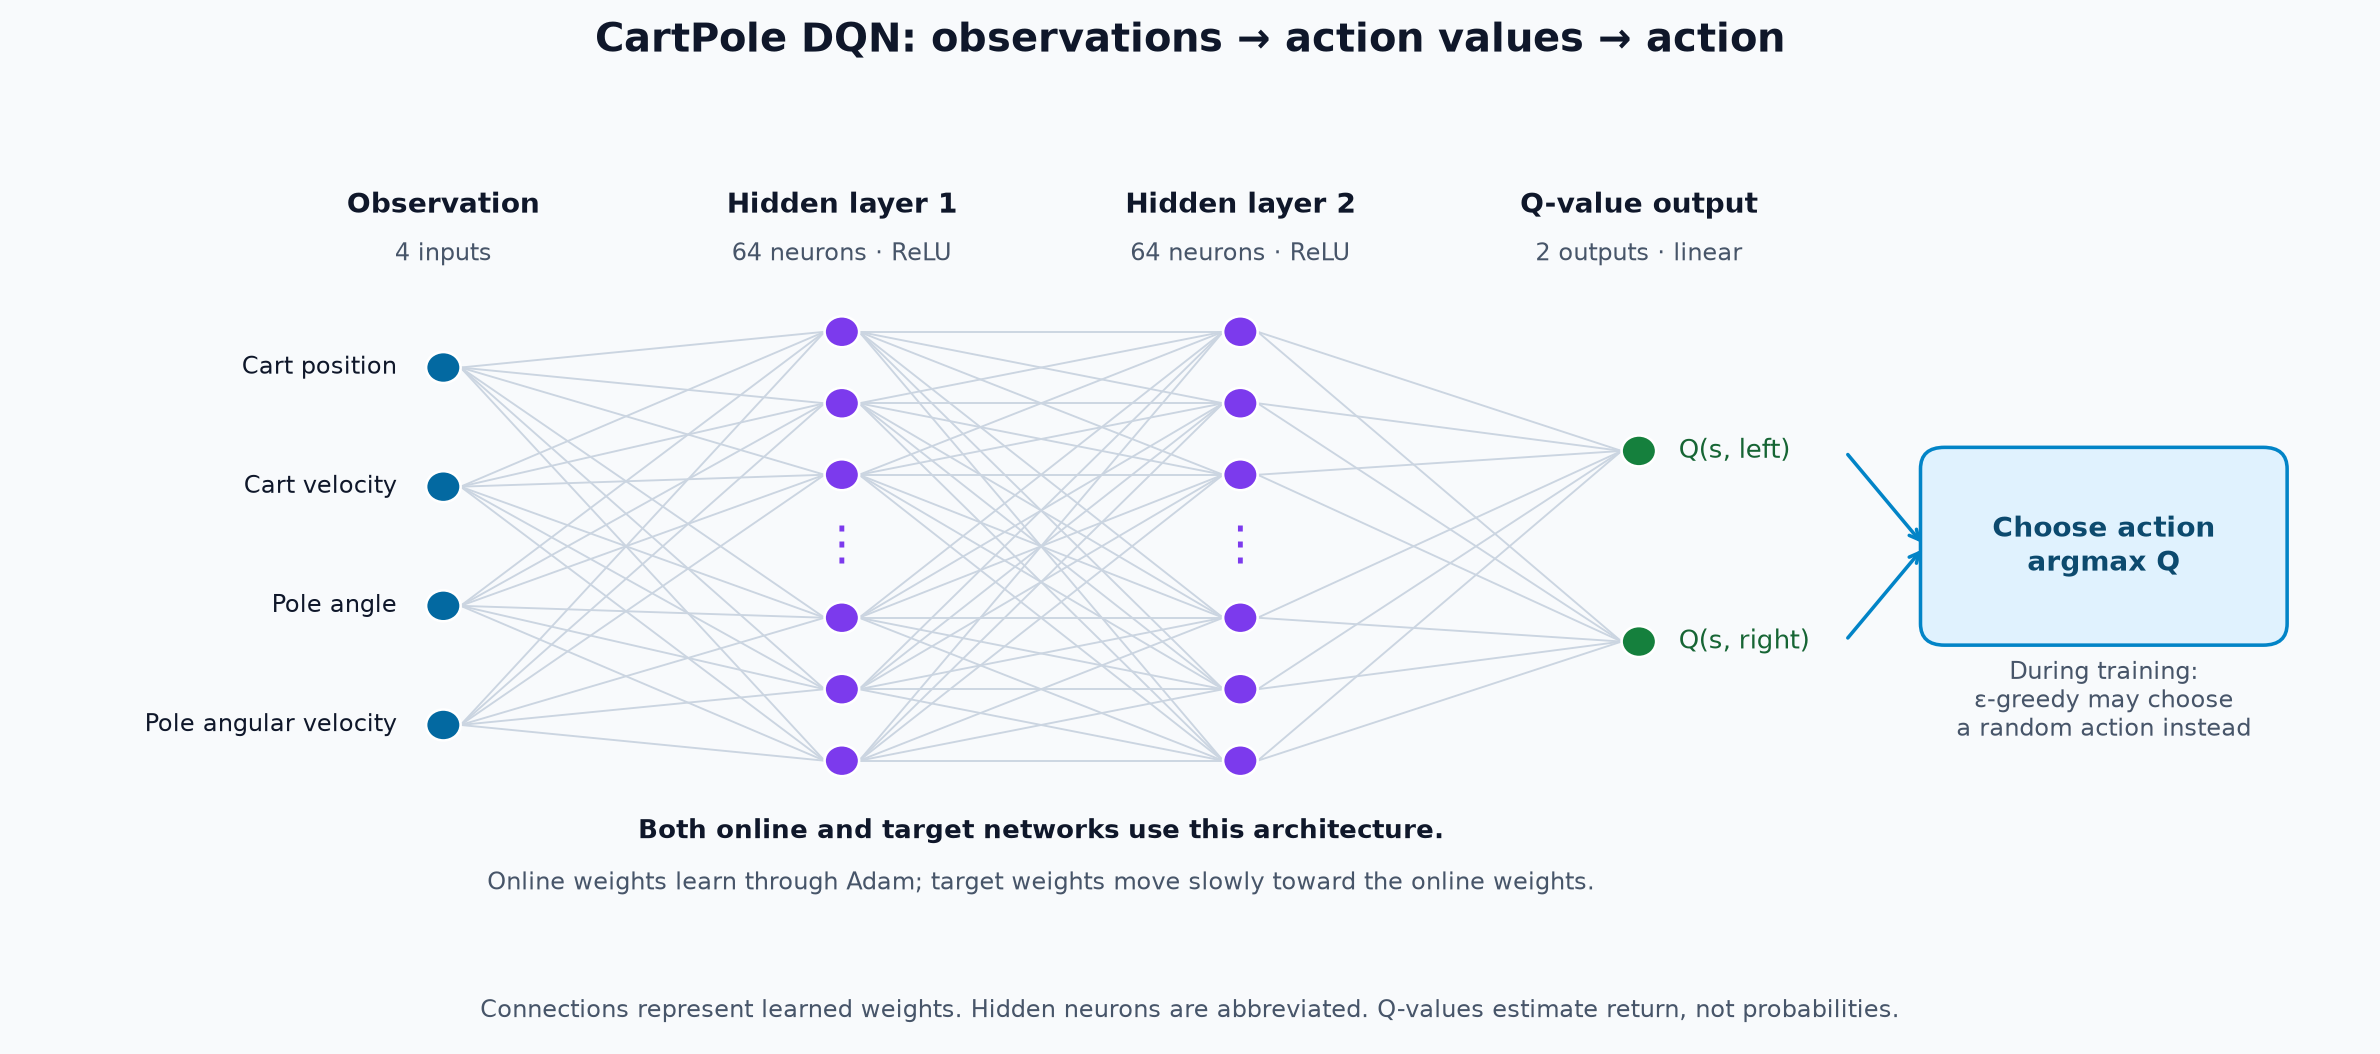

The weights and biases are the learned parameters, written $\theta$ in $Q_\theta(s,a)$. Outputs estimate **discounted future return**, not probabilities; they need not sum to one. Each minibatch row is one observation.

**Predict:** What shape should the output have for a batch of eight observations?

In [5]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

class QNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(4, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 2),
        )

    def forward(self, observations):
        return self.layers(observations)

seed_everything(TRAIN_SEED)
untrained = QNetwork().to(DEVICE)
probe = torch.tensor([[0.0, 0.0, 0.03, 0.0]], dtype=torch.float32)
with torch.no_grad():
    print("Q(left), Q(right):", untrained(probe).numpy())
    print("Greedy action:", int(untrained(probe).argmax(1).item()))
    print("Batch output shape:", tuple(untrained(torch.zeros(8, 4)).shape))
print("Trainable parameters:", sum(p.numel() for p in untrained.parameters()))

Q(left), Q(right): [[-0.08677235 -0.1595051 ]]
Greedy action: 0
Batch output shape: (8, 2)
Trainable parameters: 4610


### What makes the parameters learn?

A **loss** measures disagreement between a predicted Q-value and a Bellman target. `loss.backward()` computes parameter gradients; `optimizer.step()` changes parameters to reduce that disagreement. Adam adapts update sizes using past gradients. Unlike one Q-table entry, shared network parameters influence many predictions.

We use **Huber loss** (`SmoothL1Loss` with default threshold 1). For error $e=Q-y$, it is $\frac12e^2$ when $|e|<1$, and $|e|-\frac12$ otherwise. It is less sensitive to large errors than squared loss. Reducing this loss on a batch does not guarantee an improved policy.

**Predict:** With predicted Q=2 and target=3, what are the error and Huber loss?

In [6]:
predicted, target_value = torch.tensor([2.0]), torch.tensor([3.0])
print("Error:", (predicted - target_value).item())
print("Huber loss:", nn.functional.smooth_l1_loss(predicted, target_value).item())

Error: -1.0
Huber loss: 0.5


## 4. The DQN update (15 min)

**Replay memory** stores past transitions $(s,a,r,s',\text{terminated})$. Uniformly sampled minibatches reuse experience and reduce the strong sequential correlation of consecutive steps. Replay does not create new experience or guarantee independent samples.

The **online network** chooses greedy actions and receives gradient updates. A separate **target network** supplies future-value estimates and moves gradually toward the online network. This slows changes in the target we are trying to fit; it does not eliminate all instability.

### How the two networks form the training loss

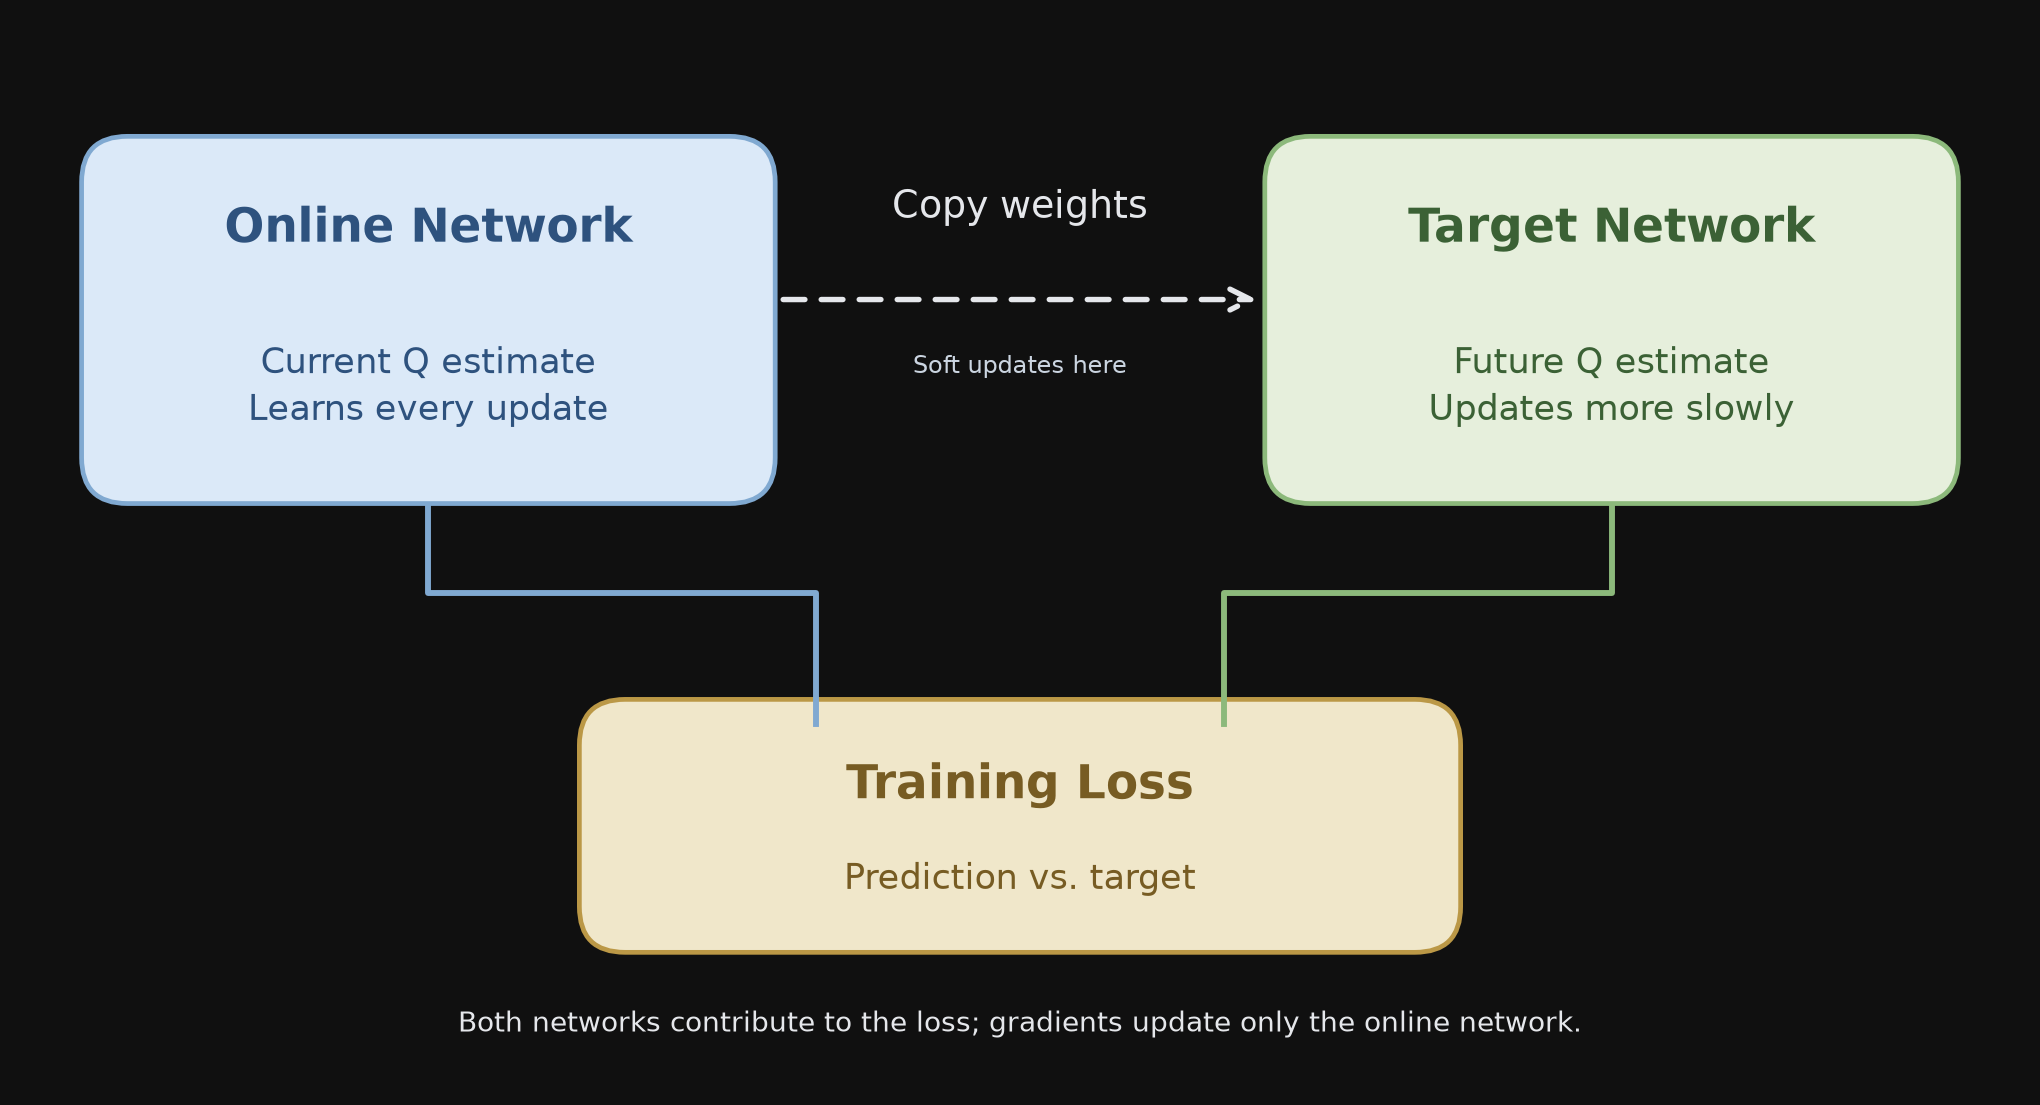

*Diagram recreated from the supplied reference. Both networks supply numbers for the loss, but only the online network receives gradients.*

Read the diagram for a replayed transition $(s,a,r,s')$:

1. **Online network — prediction:** compute $Q_\theta(s,a)$ for the action actually taken. In code, `gather` selects that action's Q-value from the two outputs.
2. **Target network — learning target:** evaluate the next observation $s'$ and use its largest Q-value in $y=r+\gamma(1-\text{terminated})\max_{a'}Q_{\theta^-}(s',a')$. The target includes the observed reward; the target network alone does not produce the entire target.
3. **Training loss — compare:** Huber loss measures disagreement between the online prediction and $y$. `loss.backward()` and `optimizer.step()` update **only the online weights**. The target is computed without gradients, so it is treated as fixed for that update.
4. **Weight transfer — follow slowly:** after the online update, `soft_update()` moves the target weights toward the online weights. The dashed arrow means this parameter transfer, not a gradient path. Here the rule is $\theta^-\leftarrow(1-\tau)\theta^-+\tau\theta$ with $\tau=0.005$, rather than a full copy at every step. The RLlib companion instead uses periodic hard copies.

**Check your understanding:** If both networks contribute to the loss, why don't we train both using `optimizer.step()`? Which line updates the target network instead?

$$y=r+\gamma(1-\text{terminated})\max_{a'}Q_{\theta^-}(s',a')$$
$$L=\operatorname{mean}\,\mathrm{Huber}(Q_\theta(s,a)-y)$$

At a genuine failure, the future term is zero. At CartPole's external time limit, the underlying balancing task could continue, so we bootstrap from the final observation. **Both flags end the rollout; only `terminated` masks the target.** We retain the final next observation before resetting.

**Hand calculation:** reward=1, best next Q=4, discount=0.99. Predict the target for (a) an ordinary transition, (b) failure, (c) time-limit truncation.

In [7]:
@dataclass(frozen=True)
class DQNConfig:
    total_steps: int = 40000
    replay_capacity: int = 10000
    warmup_steps: int = 1000
    batch_size: int = 128
    gamma: float = 0.99
    learning_rate: float = 0.0005
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_steps: int = 20000
    tau: float = 0.005
    log_every: int = 5000

class ReplayBuffer:
    def __init__(self, capacity):
        self.memory = deque(maxlen=capacity)

    def add(self, obs, action, reward, next_obs, terminated):
        self.memory.append((obs.copy(), action, reward, next_obs.copy(), terminated))

    def sample(self, size, rng):
        indices = rng.choice(len(self.memory), size=size, replace=False)
        columns = list(zip(*(self.memory[int(i)] for i in indices)))
        states, actions, rewards, next_states, terminals = columns
        return (
            torch.as_tensor(np.array(states), dtype=torch.float32),
            torch.as_tensor(actions, dtype=torch.int64),
            torch.as_tensor(rewards, dtype=torch.float32),
            torch.as_tensor(np.array(next_states), dtype=torch.float32),
            torch.as_tensor(terminals, dtype=torch.float32),
        )

    def __len__(self):
        return len(self.memory)

def epsilon_at(step, config):
    fraction = min(step / config.epsilon_decay_steps, 1.0)
    return config.epsilon_start + fraction * (config.epsilon_end - config.epsilon_start)

def choose_action(model, obs, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(2))
    with torch.no_grad():
        return int(model(torch.as_tensor(obs).unsqueeze(0)).argmax(1).item())

@torch.no_grad()
def bellman_targets(target_network, rewards, next_states, terminals, gamma):
    best_next = target_network(next_states).max(dim=1).values
    return rewards + gamma * (1.0 - terminals) * best_next

@torch.no_grad()
def soft_update(target_network, online_network, tau):
    # tau=0.005 transfers 0.5% of the parameter difference per update.
    for target_param, online_param in zip(target_network.parameters(), online_network.parameters()):
        target_param.lerp_(online_param, tau)

def optimize_batch(online, target_network, optimizer, batch, gamma):
    states, actions, rewards, next_states, terminals = batch
    predictions = online(states).gather(1, actions.unsqueeze(1)).squeeze(1)
    targets = bellman_targets(target_network, rewards, next_states, terminals, gamma)
    loss = nn.functional.smooth_l1_loss(predictions, targets)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(online.parameters(), 10.0)
    optimizer.step()  # This changes the learned Q function.
    return float(loss.item())

rewards = torch.ones(3)
terminals = torch.tensor([0.0, 1.0, 0.0])
print("Targets [ordinary, failure, time limit]:",
      (rewards + 0.99 * (1 - terminals) * 4).tolist())

Targets [ordinary, failure, time limit]: [4.960000038146973, 1.0, 4.960000038146973]


### Inspect one real update
Collect 128 random transitions, then update a **demonstration copy** of the network. The initial network used for the before/after comparison stays frozen. Inspect the batch shapes and parameter changes.

**Predict:** Will the target network change during `optimizer.step()`? When will it change?

In [8]:
demo_online = deepcopy(untrained)
demo_target = deepcopy(demo_online).requires_grad_(False)
demo_optimizer = torch.optim.Adam(demo_online.parameters(), lr=DQNConfig().learning_rate)
demo_buffer = ReplayBuffer(256)
demo_rng = np.random.default_rng(101)
env = gym.make("CartPole-v1")
try:
    obs, _ = env.reset(seed=101)
    for _ in range(128):
        action = int(demo_rng.integers(2))
        next_obs, reward, terminated, truncated, _ = env.step(action)
        demo_buffer.add(obs, action, reward, next_obs, terminated)
        obs = next_obs
        if terminated or truncated:
            obs, _ = env.reset()
finally:
    env.close()
batch = demo_buffer.sample(128, demo_rng)
print("Batch [states, actions, rewards, next states, terminals]:", [tuple(x.shape) for x in batch])
old_online = [p.clone() for p in demo_online.parameters()]
old_target = [p.clone() for p in demo_target.parameters()]
loss = optimize_batch(demo_online, demo_target, demo_optimizer, batch, 0.99)
change = sum((p - old).abs().sum().item() for p, old in zip(demo_online.parameters(), old_online))
print("Loss:", loss, "Total absolute parameter change:", change)
assert change > 0
assert all(torch.equal(p, old) for p, old in zip(demo_target.parameters(), old_target))
soft_update(demo_target, demo_online, DQNConfig().tau)
assert any(not torch.equal(p, old) for p, old in zip(demo_target.parameters(), old_target))
print("Target parameters changed only after soft_update().")

Batch [states, actions, rewards, next states, terminals]: [(128, 4), (128,), (128,), (128, 4), (128,)]
Loss: 0.5411078333854675 Total absolute parameter change: 1.5196395087987185
Target parameters changed only after soft_update().


## 5. Train and evaluate fairly (15 min)

The following loop makes all learning steps explicit:

1. Choose an ε-greedy action and take an environment step.
2. Save the transition; reset after either episode-ending flag.
3. After warmup, sample a replay batch and update the online network.
4. Move the target network a small amount toward the online network.

Training is bounded at 40,000 environment steps. Exploration decays by **environment steps**, independently of episode length. The final episode can be incomplete when the budget ends; its transitions still teach the network, but it is excluded from episode-return statistics.

**Before executing:** Predict how exploratory training returns will differ from greedy evaluation returns. Training may take a few minutes on a CPU; progress appears every 5,000 steps.

In [9]:
def train_dqn(config=DQNConfig(), *, seed=7, verbose=True):
    seed_everything(seed)
    rng = np.random.default_rng(seed)
    online = QNetwork().to(DEVICE)
    initial = deepcopy(online).eval().requires_grad_(False)
    target_network = deepcopy(online).eval().requires_grad_(False)
    optimizer = torch.optim.Adam(online.parameters(), lr=config.learning_rate)
    replay = ReplayBuffer(config.replay_capacity)
    episodes, losses, epsilons = [], [], []
    episode_return, episode_length = 0.0, 0
    started = time.perf_counter()
    env = gym.make("CartPole-v1")
    try:
        obs, _ = env.reset(seed=seed)
        for step in range(config.total_steps):
            epsilon = epsilon_at(step, config)
            action = choose_action(online, obs, epsilon, rng)
            next_obs, reward, terminated, truncated, _ = env.step(action)
            replay.add(obs, action, reward, next_obs, terminated)
            episode_return += reward
            episode_length += 1
            obs = next_obs
            if terminated or truncated:
                episodes.append({"step": step + 1, "return": episode_return,
                                 "length": episode_length, "terminated": terminated,
                                 "truncated": truncated})
                obs, _ = env.reset()
                episode_return, episode_length = 0.0, 0
            loss = np.nan
            if step + 1 >= config.warmup_steps and len(replay) >= config.batch_size:
                batch = replay.sample(config.batch_size, rng)
                loss = optimize_batch(online, target_network, optimizer, batch, config.gamma)
                soft_update(target_network, online, config.tau)
            losses.append(loss)
            epsilons.append(epsilon)
            if verbose and (step + 1) % config.log_every == 0:
                recent = np.mean([e["return"] for e in episodes[-20:]]) if episodes else np.nan
                print(f"step={step+1:6d} epsilon={epsilon:.3f} recent return={recent:.1f}", flush=True)
    finally:
        env.close()
    seconds = time.perf_counter() - started
    if verbose:
        print(f"Training completed in {seconds:.1f}s; {len(episodes)} complete episodes")
    return {"model": online.eval(), "initial": initial, "target": target_network,
            "episodes": episodes, "losses": np.array(losses),
            "epsilons": np.array(epsilons), "seconds": seconds, "config": config, "seed": seed}

In [10]:
result = train_dqn(seed=TRAIN_SEED)
trained = result["model"]
untrained = result["initial"]  # Exact initial weights from this training run.

step=  5000 epsilon=0.763 recent return=36.0


step= 10000 epsilon=0.525 recent return=18.4


step= 15000 epsilon=0.288 recent return=41.3


step= 20000 epsilon=0.050 recent return=83.2


step= 25000 epsilon=0.050 recent return=69.3


step= 30000 epsilon=0.050 recent return=64.8


step= 35000 epsilon=0.050 recent return=83.2


step= 40000 epsilon=0.050 recent return=54.1


Training completed in 47.8s; 894 complete episodes


### Read the training curves
The 20-episode rolling average describes training with exploration. Loss is averaged over blocks of 500 updates; the initial warmup has no updates. Neither curve substitutes for evaluation.

**Inspect:** Is improvement monotonic? If loss falls but evaluation return does not rise, have we demonstrated better control?

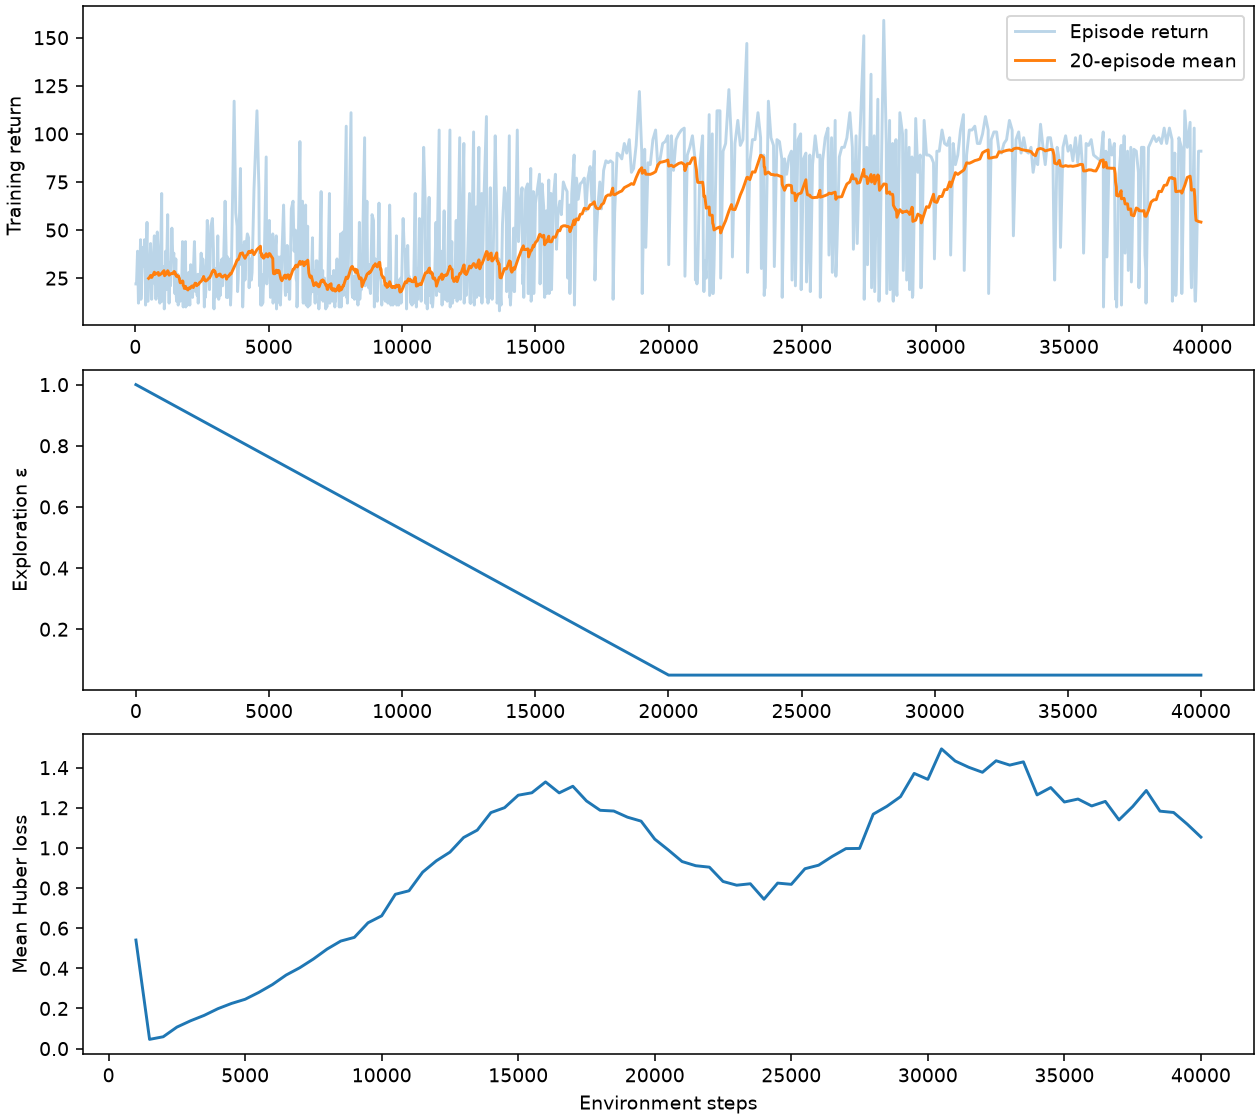

In [11]:
def plot_training(result, path):
    fig, axes = plt.subplots(3, 1, figsize=(9, 8), constrained_layout=True)
    steps = np.array([e["step"] for e in result["episodes"]])
    returns = np.array([e["return"] for e in result["episodes"]])
    axes[0].plot(steps, returns, alpha=0.3, label="Episode return")
    if len(returns) >= 20:
        axes[0].plot(steps[19:], np.convolve(returns, np.ones(20)/20, mode="valid"),
                     label="20-episode mean")
    axes[0].set_ylabel("Training return")
    axes[0].legend()
    axes[1].plot(np.arange(1, len(result["epsilons"])+1), result["epsilons"])
    axes[1].set_ylabel("Exploration ε")
    losses = result["losses"]
    blocks = [(i + len(losses[i:i+500]), losses[i:i+500]) for i in range(0, len(losses), 500)]
    valid = [(x, np.mean(y[np.isfinite(y)])) for x, y in blocks if np.isfinite(y).any()]
    if valid:
        axes[2].plot(*zip(*valid))
    axes[2].set_ylabel("Mean Huber loss")
    axes[2].set_xlabel("Environment steps")
    fig.savefig(path, dpi=140)
    plt.close(fig)
    display(Image(filename=str(path)))

plot_training(result, OUTPUT / "learning_curve.png")

### Same 20 starting seeds, three frozen policies
Evaluate random, initial untrained, and trained policies on the **same 20 reset seeds**. Random actions use a separate RNG. Neural policies are greedy, with gradients disabled and no learning updates.

Report mean return and its standard deviation **across evaluation episodes**, plus mean episode length and the fraction reaching the time limit. Here return equals episode length because each step pays +1; these metrics would differ under another reward scheme. Reaching the cap is not proof of unlimited balancing or unseen-task generalization. Evaluation return is undiscounted; the network estimates discounted return.

**Predict:** Which policy will have the highest mean? Could some initial states still fail early?

Policy        Mean return   Std return  Mean length   Time limit
random               26.0          7.5         26.0           0%
untrained             9.3          0.7          9.3           0%
trained             101.0          5.0        101.0           0%


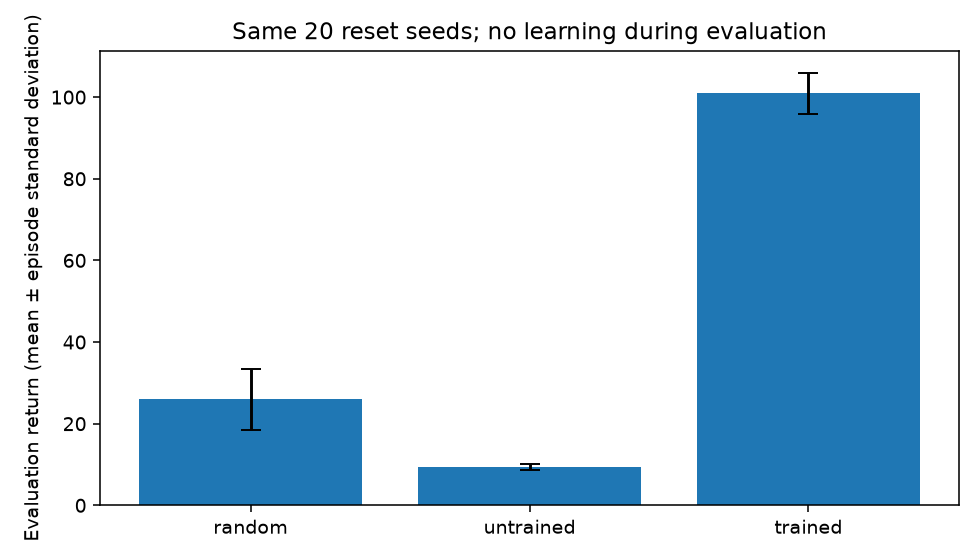

In [12]:
def evaluate(model=None, *, seeds=EVAL_SEEDS):
    rows = []
    env = gym.make("CartPole-v1")
    try:
        with torch.no_grad():
            for seed in seeds:
                rng = np.random.default_rng(seed + 10000)
                obs, _ = env.reset(seed=int(seed))
                total, length = 0.0, 0
                while True:
                    action = (int(rng.integers(2)) if model is None else
                              int(model(torch.as_tensor(obs).unsqueeze(0)).argmax(1).item()))
                    obs, reward, terminated, truncated, _ = env.step(action)
                    total += reward
                    length += 1
                    if terminated or truncated:
                        rows.append({"seed": seed, "return": total, "length": length,
                                     "time_limit": bool(truncated and not terminated)})
                        break
    finally:
        env.close()
    returns = np.array([r["return"] for r in rows])
    return {"mean_return": float(returns.mean()), "std_return": float(returns.std(ddof=1)),
            "mean_length": float(np.mean([r["length"] for r in rows])),
            "time_limit_fraction": float(np.mean([r["time_limit"] for r in rows])),
            "episodes": len(rows)}

metrics = {"random": evaluate(), "untrained": evaluate(untrained), "trained": evaluate(trained)}
with (OUTPUT / "metrics.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=["policy", *metrics["random"]])
    writer.writeheader()
    for policy, values in metrics.items():
        writer.writerow({"policy": policy, **values})
print(f"{'Policy':12s} {'Mean return':>12s} {'Std return':>12s} {'Mean length':>12s} {'Time limit':>12s}")
for name, values in metrics.items():
    print(f"{name:12s} {values['mean_return']:12.1f} {values['std_return']:12.1f} "
          f"{values['mean_length']:12.1f} {values['time_limit_fraction']:12.0%}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(list(metrics), [m["mean_return"] for m in metrics.values()],
       yerr=[m["std_return"] for m in metrics.values()], capsize=5)
ax.set_ylabel("Evaluation return (mean ± episode standard deviation)")
ax.set_title("Same 20 reset seeds; no learning during evaluation")
fig.tight_layout()
fig.savefig(OUTPUT / "policy_comparison.png", dpi=140)
plt.close(fig)
display(Image(filename=str(OUTPUT / "policy_comparison.png")))

### Watch before and after
Both previews start from seed 2026 and show at most 125 frames. Use the full evaluation table to judge performance; a short successful clip alone is insufficient evidence.

In [13]:
display(animate_policy(untrained, seed=EVAL_SEEDS[0], title="Before training"))
display(animate_policy(trained, seed=EVAL_SEEDS[0], title="After training"))

## 6. Explain what you learned (5 min)

1. Why is a Q-table awkward for continuous observations? What tradeoff does discretization make?
2. What are the network's four inputs and two outputs? Why are the outputs not probabilities?
3. Which line changes the online network's parameters? How is that different from Lesson 01's table update?
4. What problems do replay memory and the target network address?
5. Why do we reset after truncation while still including the future-value term?
6. What does the three-policy evaluation support? What remains uncertain after one training seed?
7. Can standard DQN directly choose an arbitrary real-valued force? Explain the discrete-action requirement.

**Submit:** one learning or comparison plot, `metrics.csv`, your advance prediction, and 3–5 sentences interpreting the evidence.

> I predicted ... . The random, untrained, and trained mean returns were ... .
> The evaluation supports ... because ... .
> The learned quantities were ... . Replay helps by ... and the target network helps by ... .
> One limitation of this experiment is ... .

## Optional homework — less experience versus more experience
Change only the environment-step budget. Use the same training seed, evaluation seeds, network, and exploration schedule. A shorter run also stops earlier along that fixed exploration schedule; state this when interpreting the results. The full run above is the long condition, so do not retrain it unnecessarily.

**Write a prediction first.** Execute the example below in a new cell:

```python
from dataclasses import replace
short_result = train_dqn(replace(result["config"], total_steps=5000), seed=TRAIN_SEED)
print("Short:", evaluate(short_result["model"]))
print("Long: ", metrics["trained"])
```

For a stronger conclusion, repeat both budgets for training seeds **7, 11, 23** and report the spread of evaluation means. Do not select a favorable run to represent every seed. Keep the provided evaluation set for the classroom comparison; use a separate test set if tuning parameters against it.

### Optional extension — DQN with Ray RLlib

Open [the standalone RLlib companion](../../lessons/lesson02_dqn/Lesson_02_DQN_RLlib.ipynb) to let a library manage replay, exploration, target networks, and optimization. It uses the same CartPole task, network shape, and evaluation seeds, with explicit explanations of configuration differences. The companion requires the workshop's pinned Ray RLlib 2.59.0 and runs on CPU.

### References

- [Gymnasium: CartPole specification](https://gymnasium.farama.org/environments/classic_control/cart_pole/) — observations, actions, rewards, and episode endings.
- [Gymnasium: basic usage](https://gymnasium.farama.org/introduction/basic_usage/) — `make`, `reset`, `step`, rendering, and closing.
- [Gymnasium: handling time limits](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/) — bootstrapping and episode boundaries.
- [PyTorch: Reinforcement Learning (DQN) Tutorial](https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning.html) — replay, neural action values, and target networks.

**Connection forward:** The same Gymnasium contract supports the workshop's custom navigation environment. Its observation dimensions and action count differ, so this CartPole-specific network would need adapting.